<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization | Exploring Developer Survey Responses**
**IBM Skills Network guided lab | Portfolio edition**


### Project Overview
Charts can make a large dataset easier to understand, but their usefulness depends on how the data is prepared and what the chart actually measures. In this project, I use SQL and Python to explore responses from a developer survey and present several aspects of the data visually.

**Guiding question:** What can survey responses tell us about developers' demographics, compensation, experience, and technology interests?

**Approach:** Load survey data → Store it in SQLite → Query the fields needed for each question → Build visualizations → Evaluate what the charts do and do not show.

**Skills:** SQL, SQLite, Pandas, Matplotlib, Seaborn, data selection, aggregation, and data visualization.

*This notebook follows an IBM Skills Network guided lab. The original code, learning exercises, and attribution are retained; the additional explanations are intended to make the analysis accessible to a portfolio audience.*

Estimated time needed: **45** minutes


### Objectives


After completing this lab, you will be able to:
-   Visualize the distribution of data.
-   Visualize the relationship between two features.
-   Visualize composition and comparison of data.

### Demo: How to work with database


The lab begins by downloading a survey CSV file. Rather than working only with the CSV, I will also load it into a SQLite database. This makes it possible to practice writing SQL queries to select exactly the records needed for each visualization.

In [63]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

--2026-10-16 14:17:45--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv.6’


survey-data.csv.6     0%[                    ]       0  --.-KB/s               
survey-data.csv.6     2%[                    ]   4.52M  5.52MB/s               
survey-data.csv.6     5%[>                   ]   8.04M  5.28MB/s               
survey-data.csv.6     8%[>                   ]  13.65M  6.20MB/s               
survey-data.csv.6    14%[=>                  ]  21.69M  7.25MB/s               
survey-data.csv.6    17%[==>         

**Install and Import Necessary Python Libraries**

Ensure that you have the required libraries installed to work with SQLite and Pandas:


In [1]:
!pip install pandas 
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 149.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 136.4 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━

**Read the CSV File into a Pandas DataFrame**

Load the Stack Overflow survey data into a Pandas DataFrame:


In [3]:
# Read the CSV file
df = pd.read_csv('survey-data.csv')

# Display the first few rows of the data
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


**Create a SQLite Database and Insert the Data**

Now, let's create a new SQLite database (`survey-data.sqlite`) and insert the data from the DataFrame into a table using the sqlite3 library:


In [ ]:
import sqlite3

# Create a connection to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Write the dataframe to the SQLite database
df.to_sql('main', conn, if_exists='replace', index=False)

**Verify the Data in the SQLite Database**
Verify that the data has been correctly inserted into the SQLite database by running a simple query:


In [85]:
# Reconnect to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Run a simple query to check the data
QUERY = "SELECT * FROM main LIMIT 5"
df_check = pd.read_sql_query(QUERY, conn)

# Display the results
print(df_check)

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

### Demo: Running an SQL Query


Count the number of rows in the table named 'main'


In [49]:
QUERY = """
SELECT COUNT(*) 
FROM main
"""
df = pd.read_sql_query(QUERY, conn)
df.head()

,COUNT(*)
0,65437


A simple COUNT(*) query tells me how many records are stored in the table. The saved result shows 65,437 rows. This provides useful context for the charts, although different questions can have different numbers of valid answers.

### Demo: Listing All Tables


To view the names of all tables in the database:


In [50]:
QUERY = """
SELECT name as Table_Name FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)

,Table_Name
0,main


Grouping responses by Age gives a count for each reported age category. In the saved results, the 25-34 years old category is the largest, with 23,911 responses, followed by 35-44 years old with 14,942. These are survey counts, not estimates of the age distribution of all developers.

### Demo: Running a Group By Query
    
For example, you can group data by a specific column, like Age, to get the count of respondents in each age group:


In [51]:
QUERY = """
SELECT Age, COUNT(*) as count
FROM main
GROUP BY Age
ORDER BY Age
"""
pd.read_sql_query(QUERY, conn)

,Age,count
0,18-24 years old,14098
1,25-34 years old,23911
2,35-44 years old,14942
3,45-54 years old,6249
4,55-64 years old,2575
5,65 years or older,772
6,Prefer not to say,322
7,Under 18 years old,2568


### Demo: Describing a table

Use this query to get the schema of a specific table, main in this case:


In [52]:
table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

df = pd.read_sql_query(QUERY, conn)
print(df.iat[0,0])

CREATE TABLE "main" (
"ResponseId" INTEGER,
  "MainBranch" TEXT,
  "Age" TEXT,
  "Employment" TEXT,
  "RemoteWork" TEXT,
  "Check" TEXT,
  "CodingActivities" TEXT,
  "EdLevel" TEXT,
  "LearnCode" TEXT,
  "LearnCodeOnline" TEXT,
  "TechDoc" TEXT,
  "YearsCode" TEXT,
  "YearsCodePro" TEXT,
  "DevType" TEXT,
  "OrgSize" TEXT,
  "PurchaseInfluence" TEXT,
  "BuyNewTool" TEXT,
  "BuildvsBuy" TEXT,
  "TechEndorse" TEXT,
  "Country" TEXT,
  "Currency" TEXT,
  "CompTotal" REAL,
  "LanguageHaveWorkedWith" TEXT,
  "LanguageWantToWorkWith" TEXT,
  "LanguageAdmired" TEXT,
  "DatabaseHaveWorkedWith" TEXT,
  "DatabaseWantToWorkWith" TEXT,
  "DatabaseAdmired" TEXT,
  "PlatformHaveWorkedWith" TEXT,
  "PlatformWantToWorkWith" TEXT,
  "PlatformAdmired" TEXT,
  "WebframeHaveWorkedWith" TEXT,
  "WebframeWantToWorkWith" TEXT,
  "WebframeAdmired" TEXT,
  "EmbeddedHaveWorkedWith" TEXT,
  "EmbeddedWantToWorkWith" TEXT,
  "EmbeddedAdmired" TEXT,
  "MiscTechHaveWorkedWith" TEXT,
  "MiscTechWantToWorkWith" TEXT,


### Hands-on Lab

### Visualizing the Distribution of Data

**Histograms**

Plot a histogram of CompTotal (Total Compensation).

Here, the code selects non-missing CompTotal values and excludes observations above the 95th percentile before drawing the chart. This makes the main concentration of values easier to see, but it also means the highest 5% of reported values are not shown.

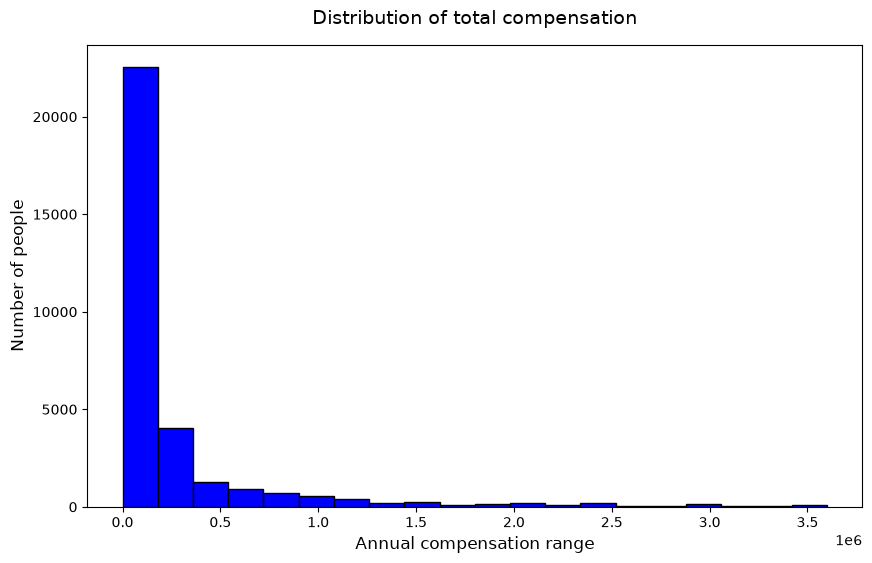

In [53]:
## Write your code here
query = "SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL"
df_comp = pd.read_sql_query(query, conn)
df_comp['CompTotal'] = pd.to_numeric(df_comp['CompTotal'], errors='coerce')
df_comp = df_comp.dropna(subset=['CompTotal'])

upper_limit = df_comp['CompTotal'].quantile(0.95)
df_filtered = df_comp[df_comp['CompTotal'] <= upper_limit]
plt.clf()
plt.close('all')

plt.figure(figsize=(10, 6))
plt.hist(df_filtered['CompTotal'], bins=20, color='blue', edgecolor='black')
plt.title('Distribution of total compensation', fontsize=14, pad=15)
plt.xlabel('Annual compensation range', fontsize=12)
plt.ylabel('Number of people', fontsize=12)
plt.show()

**Interpretation note:** CompTotal is the amount of compensation reported by respondents, and those amounts may be in different currencies and pay periods. This chart should therefore not be interpreted as a comparable annual salary distribution without additional cleaning and conversion.

**Box Plots**

Plot a box plot of Age. A box plot summarizes the middle portion of a numeric distribution and its spread. It is useful when the underlying data represents actual numeric measurements.

In this survey, however, Age contains categories such as "25-34 years old". The code extracts the first number from each label, turning that category into 25. The resulting box plot therefore shows the distribution of category lower bounds, not respondent's exact ages. It also hides outlier markers using `showfliers=False`.

This is a helpful charting exercise, but a bar chart of the original age categories would be a more faithful way to present the survey responses.

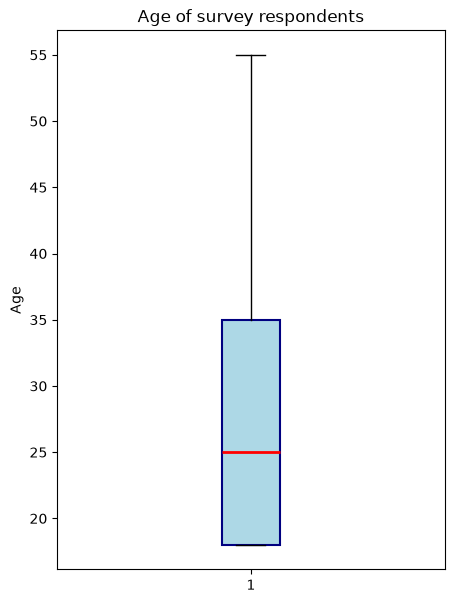

In [57]:
plt.clf()
plt.close('all')
df_raw = pd.read_sql_query("SELECT Age FROM main WHERE Age IS NOT NULL", conn)

#Extract the first number from text ranges (e.g., '25-34 years old' becomes 25)
df_raw['Clean_age'] = df_raw['Age'].astype(str).str.extract(r'(\d+)').astype(float)
df_clean = df_raw.dropna(subset=['Clean_age'])

plt.figure(figsize=(5, 7))
plt.boxplot(df_clean['Clean_age'], patch_artist=True, showfliers=False,
            boxprops=dict(facecolor='lightblue', color='navy', linewidth=1.5),
            medianprops=dict(color='red', linewidth=2))
plt.title('Age of survey respondents')
plt.ylabel('Age')
plt.show()

### Visualizing Relationships in Data

**Scatter Plots**

Create a scatter plot of `Age` and `WorkExp`. A scatter plot can help reveal whether two numeric variables tend to move together. This exercise compares the Age and WorkExp fields.

**Interpretation note:** The `Age` column contains text categories rather than precise ages. Because the code plots those labels directly, the horizontal axis is categorical. This is not a conventional numeric age-versus-experience scatter plot, so it cannot support a reliable conclusion about the strength of their relationship. A stronger analysis would use valid numeric age estimates or compare experience distributions across age groups.

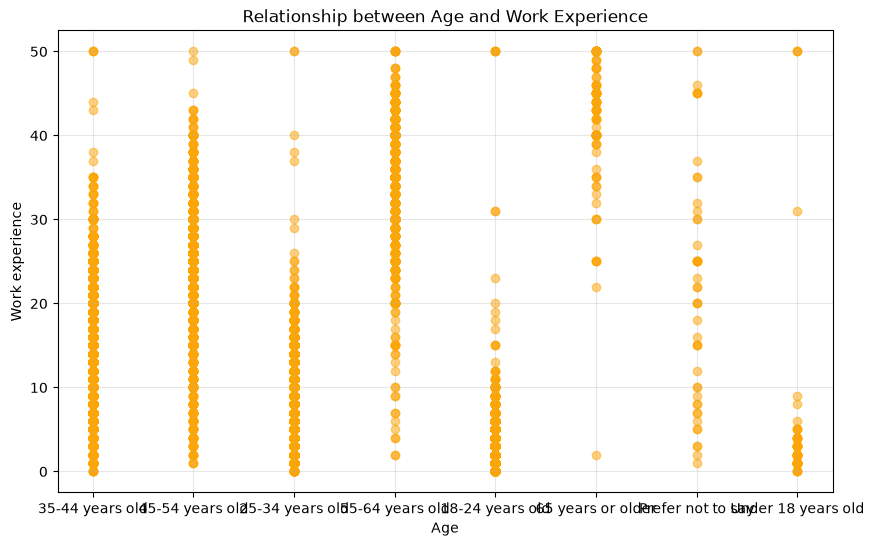

In [58]:
## Write your code here
query = "SELECT Age, WorkExp FROM main WHERE Age IS NOT NULL AND WorkExp IS NOT NULL"
df_scatter = pd.read_sql_query(query, conn)

plt.figure(figsize=(10, 6))
plt.scatter(df_scatter['Age'], df_scatter['WorkExp'], alpha=0.5, color='orange')
plt.title('Relationship between Age and Work Experience')
plt.xlabel('Age')
plt.ylabel('Work experience')
plt.grid(True, alpha=0.3)
plt.show()

### Visualizing Composition of Data

**Pie Charts**

Create a pie chart of the top 5 databases(`DatabaseWantToWorkWith`) that respondents wish to learn next year. A pie chart shows how selected categories divide a total. The SQL query groups respondents by the complete text stored in DatabaseWantToWorkWith and selects the five most common answers.

**Important distinction:** This survey field can contain multiple databases in one response. As written, the query counts entire answer combinations, not mentions of individual database technologies. The pie chart therefore represents the relative frequency of the five most common response strings, not the five most desired databases. To answer that second question, I would split the semicolon-separated answers and count each database separately.


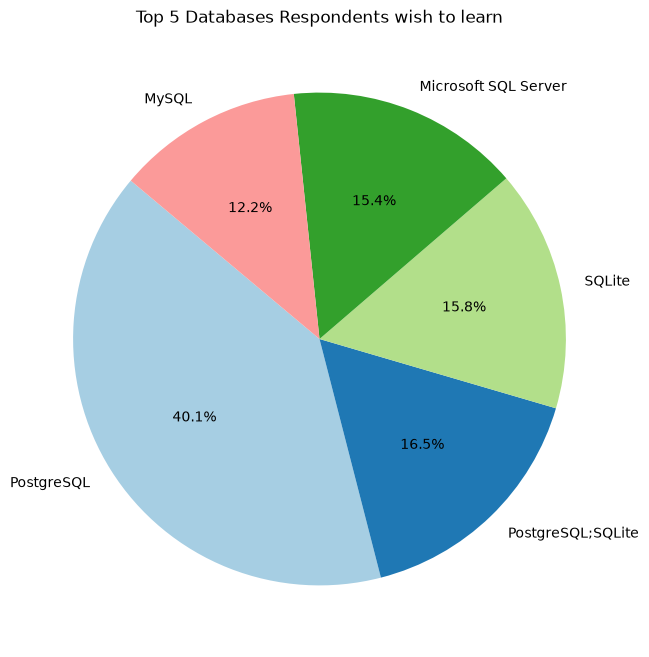

In [55]:
## Write your code here
query = """
SELECT DatabaseWantToWorkWith, COUNT(*) as Count 
FROM main 
WHERE DatabaseWantToWorkWith IS NOT NULL 
GROUP BY DatabaseWantToWorkWith 
ORDER BY Count DESC 
LIMIT 5
"""
df_pie = pd.read_sql_query(query, conn)

plt.figure(figsize=(8, 8))
plt.pie(df_pie['Count'], labels=df_pie['DatabaseWantToWorkWith'], autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title('Top 5 Databases Respondents wish to learn')
plt.show()

### Visualizing Comparison of Data

**Line Chart**

Plot the median `CompTotal` for all ages from 45 to 60. This chart calculates median CompTotal for age values selected by the code. A median is the middle reported amount, making it less sensitive to very large observations than an average.

The survey stores age as ranges, so the code extracts each range's lower bound. Its filter from 45 to 60 consequently includes the 45-54 and 55-64 groups (represented as 45 and 55), not each individual age from 45 through 60.

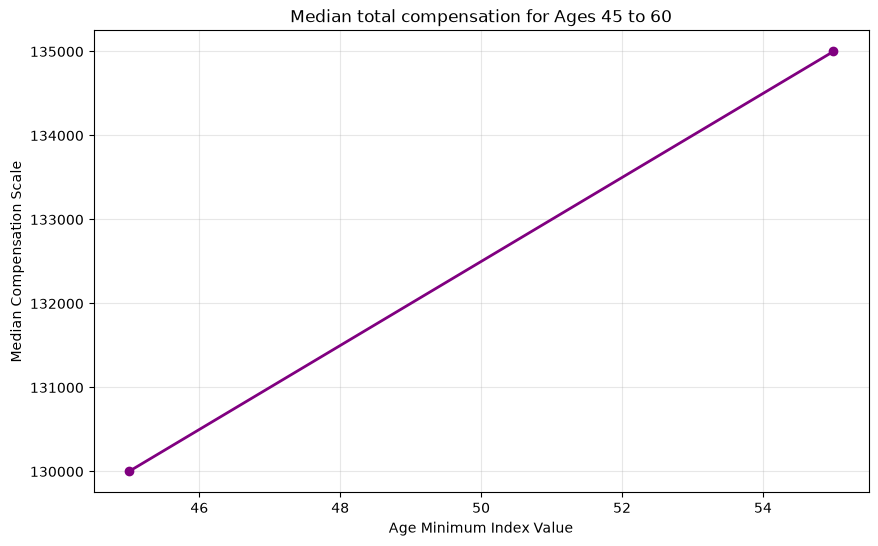

In [60]:
## Write your code here
query_line = "SELECT Age, CompTotal FROM main WHERE Age IS NOT NULL AND CompTotal IS NOT NULL"
df_line = pd.read_sql_query(query_line, conn)

df_line['Age_num'] = df_line['Age'].astype(str).str.extract(r'(\d+)').astype(float)
df_line['CompTotal'] = pd.to_numeric(df_line['CompTotal'], errors='coerce')
df_line = df_line.dropna(subset=['Age_num', 'CompTotal'])

df_filtered_line = df_line[(df_line['Age_num'] >= 45) & (df_line['Age_num'] <= 60)]

median_comp_by_age = df_filtered_line.groupby('Age_num')['CompTotal'].median().reset_index()

# Plot the Line Chart
plt.figure(figsize=(10, 6))
plt.plot(median_comp_by_age['Age_num'], median_comp_by_age['CompTotal'], marker='o', color='purple', linewidth=2)
plt.title('Median total compensation for Ages 45 to 60')
plt.xlabel('Age Minimum Index Value')
plt.ylabel('Median Compensation Scale')
plt.grid(True, alpha=0.3)
plt.show()

**Bar Chart**

Create a horizontal bar chart using the `MainBranch` column. A horizontal bar chart works well here because the category names are longer than ordinary numeric axis labels. This comparison helps show the composition of the survey sample.

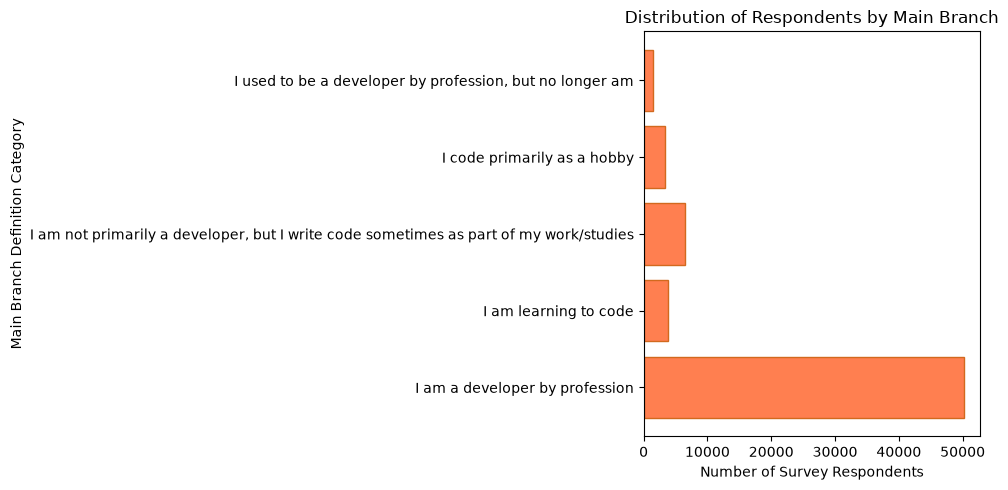

In [56]:
## Write your code here
query_bar = "SELECT MainBranch, COUNT(*) as Count FROM main WHERE MainBranch IS NOT NULL GROUP BY MainBranch"
df_bar = pd.read_sql_query(query_bar, conn)

plt.figure(figsize=(10, 5))
plt.barh(df_bar['MainBranch'], df_bar['Count'], color='coral', edgecolor='chocolate')
plt.title('Distribution of Respondents by Main Branch')
plt.xlabel('Number of Survey Respondents')
plt.ylabel('Main Branch Definition Category')
plt.tight_layout()
plt.show()

### Key Findings
- The saved SQLite query confirms 65,437 survey records.
- The largest reported age category is 25-34 years old, with 23,911 responses.
- The compensation histogram makes the central portion of the reported amounts easier to view, but excludes the highest 5% and does not standardize currencies or pay periods.
- The age box plot and age-related charts use age-category labels or lower bounds rather than exact ages.
- The database pie chart counts combinations of selected databases rather than individual database mentions.
- The MainBranch bar chart provides a straightforward comparison of survey response categories.

### Limitations and Next Steps
The purpose of this lab is to practice retrieving and visualizing data, not to establish population-wide conclusions. Some chart inputs need additional preparation before their results can be interpreted substantively. In a follow-up analysis, I would standardize compensation into a common currency and annual basis, retain age as categories where appropriate, and split multi-select database answers before counting individual technologies. I would also report the valid response count for each question.

### Skills Demonstrated
- Data access: Loading CSV data into SQLite and retrieving results with SQL.
- Data preparation: Filtering, grouping, converting types, and calculating medians.
- Visualization: Histograms, box plots, scatter plots, pie charts, line charts, and horizontal bar charts.
- Analytical judgment: Identifying when a chart's appearance may overstate what the underlying data supports.

### Summary


In this lab, you focused on extracting and visualizing data from an RDBMS using SQL queries and SQLite. You applied various visualization techniques, including:
- Histograms to display the distribution of CompTotal.
- Box plots to show the spread of ages.
- Scatter plots and bubble plots to explore relationships between variables like Age, WorkExp, `TimeSearching` and `TimeAnswering`.
- Pie charts and stacked charts to visualize the composition of data.
- Line charts and bar charts to compare data across categories.

*Original instructional content and attribution: IBM Skills Network. Portfolio explanations were added without rerunning the saved results.*

### Close the Database Connection

Once the lab is complete, ensure to close the database connection:


In [61]:
conn.close()

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
